In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import data_utils_all as du

ModuleNotFoundError: No module named 'ALL'

In [ ]:
# see the data_utils.py file 
# load_clean function loads and does basic cleaning (format, dropping Num, etc.)

df = du.load_clean("../dataset/Iisingintie_Acc1_m800_RDMC_2026-05-06_123750.txt", trim=False, continuous=False, transfix=False)

df.head()

TypeError: load_clean() got an unexpected keyword argument 'transfix'

In [ ]:
# trimming the ends of the data 
# sensor and timestamps are off and unreliable here, so they need to go
trimmed = du.trim_ends(df)

print("Kept Loc:", round(trimmed["Loc(m)"].min()), "-", round(trimmed["Loc(m)"].max()))
print("Rows:", len(df), "->", len(trimmed))

Kept Loc: 3856 - 6861
Rows: 56873 -> 56604


In [ ]:
def fix_transitions(dfcol, threshold=0.05, settle=3, tol=0.02):
    """
    Label a noisy signal with clean whole numbers (baseline 0).
    Rise: whole ramp gets the level it settles on. Drop: labelled 0.
    Stable rows: rounded.

    threshold: row-to-row change that counts as movement
    settle:    still rows needed to count as settled
    tol:       max distance from a whole number to count as on it
    """
    v = dfcol.to_numpy(dtype=float)
    out = np.rint(v).astype(int)                 # default: rounded values
    diff = np.diff(v, prepend=v[0])              # change from previous row
    changed = np.abs(diff) > threshold           # True where the signal moved

    start, direction, quiet = None, 0, 0         # transition start, +1 rise / -1 drop, still rows
    for i in range(len(v)):
        quiet = 0 if changed[i] else quiet + 1

        if changed[i] and start is None:         # a jump begins a transition
            start = i
            direction = 1 if diff[i] > 0 else -1

        # settled: no movement for `settle` rows AND on a whole number
        if start is not None and quiet >= settle and abs(v[i] - round(v[i])) <= tol:
            out[start:i + 1] = round(v[i]) if direction > 0 else 0
            start = None

    if start is not None:                        # data ended mid-transition
        out[start:] = max(round(v[-1]), 0) if direction > 0 else 0

    return pd.Series(out, index=dfcol.index)

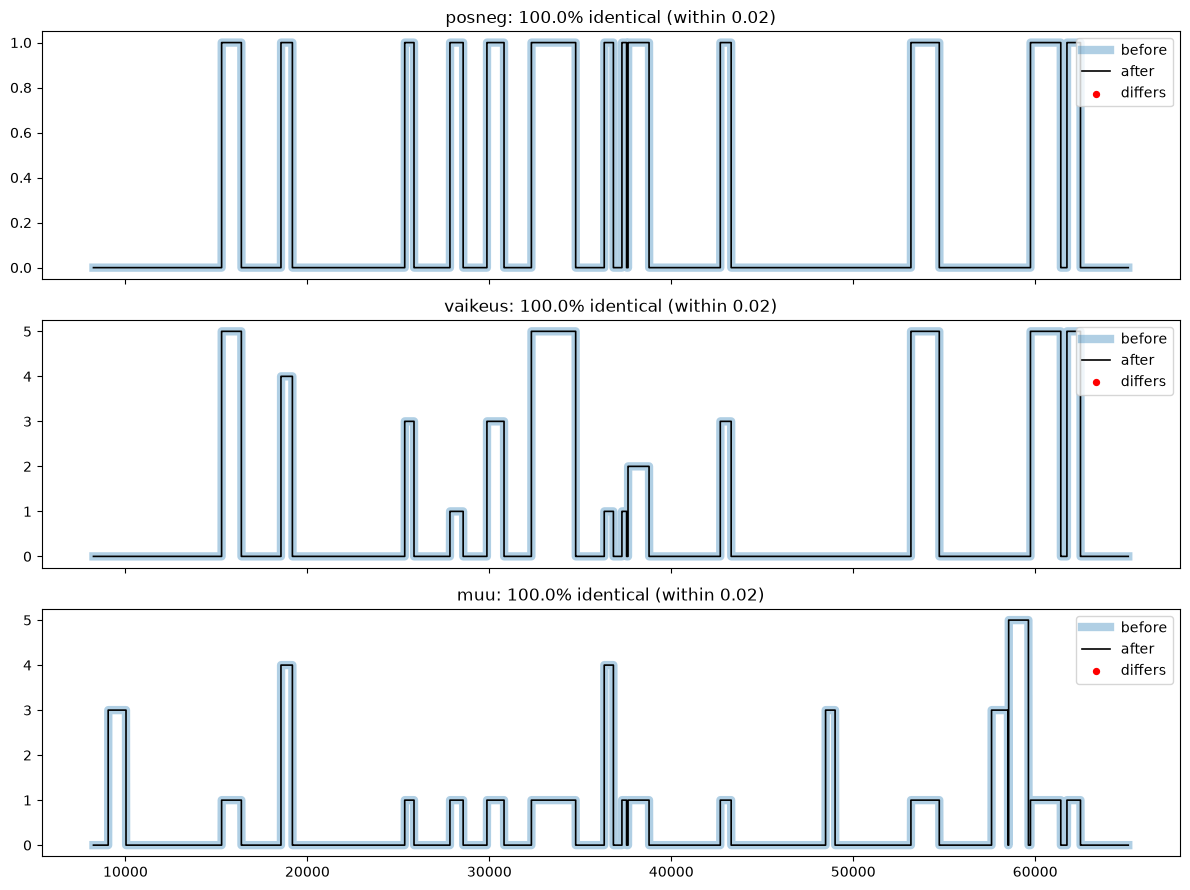

In [ ]:
cols_to_fix = ['posneg', 'vaikeus', 'muu']
df_cleaned = df.copy()

for col in cols_to_fix:
    df_cleaned[col] = fix_transitions(df_cleaned[col], threshold=0.05, settle=3, tol=0.02)


def plot_before_after(df_before, df_after, columns, tol=0.02):
    fig, axes = plt.subplots(len(columns), 1, figsize=(12, 3 * len(columns)), sharex=True, squeeze=False)
    for ax, col in zip(axes[:, 0], columns):
        b, a = df_before[col], df_after[col]
        same = (b - a).abs() <= tol

        # before: thick and light underneath, after: thin and dark on top.
        # Where they overlap, the thin line sits inside the thick one.
        ax.plot(b.index, b, color="tab:blue", linewidth=6, alpha=0.35, label="before")
        ax.step(a.index, a, where="post", color="black", linewidth=1.2, label="after")

        # red dots mark rows where they differ by more than tol
        ax.scatter(b.index[~same], b[~same], color="red", s=18, zorder=3, label="differs")

        ax.set_title(f"{col}: {same.mean():.1%} identical (within {tol})")
        ax.legend(loc="upper right")
    plt.tight_layout()
    plt.show()

plot_before_after(df, df_cleaned, cols_to_fix)